In [1]:
#import required librabries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#loading datasets
air = pd.read_csv(r"C:\Users\reddy\OneDrive\Desktop\ML\Dataset\air_quality_daily.csv")
cities = pd.read_csv(r"C:\Users\reddy\OneDrive\Desktop\ML\Dataset\cities.csv")
weather = pd.read_csv(r"C:\Users\reddy\OneDrive\Desktop\ML\Dataset\weather_daily.csv")

In [3]:
#convert dates
air["date"] = pd.to_datetime(air["date"])
weather["date"] = pd.to_datetime(weather["date"])

print("All datasets are loaded")
print(air.shape, cities.shape, weather.shape)

All datasets are loaded
(77400, 19) (50, 6) (124750, 14)


In [4]:
#merge air quality and weather
merged = pd.merge(
    air,
    weather,
    on = ["date", "city"],
    how = "left",
    validate = "one_to_one"
)

#Add geographical information
merged = pd.merge(
    merged,
    cities,
    on = "city",
    how = "left",
    validate = "many_to_one"
)

merged = merged.sort_values(
    ["city", "date"]
).reset_index(drop = True)

print("Integrated dataset:", merged.shape)
display(merged.head())

Integrated dataset: (77400, 36)


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code,state,region,latitude,longitude,elevation_m
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,...,10.5,150,21.19,4.63,63,Tripura,Northeast,23.8315,91.2868,12.0
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,...,8.8,125,17.90,3.89,63,Tripura,Northeast,23.8315,91.2868,12.0
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,...,11.5,160,23.91,5.31,51,Tripura,Northeast,23.8315,91.2868,12.0
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,...,17.4,123,20.32,4.55,63,Tripura,Northeast,23.8315,91.2868,12.0
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,...,19.4,144,22.10,5.08,61,Tripura,Northeast,23.8315,91.2868,12.0


In [5]:
merged = merged.sort_values(["city", "date"]).copy()

next_date = merged.groupby("city")["date"].shift(-1)

date_gaps = (next_date - merged["date"]).dt.days

print("Date gaps:")
print(date_gaps.value_counts().sort_index())

print(
    "Non-consecutive dates:",
    (date_gaps.notna() & (date_gaps != 1)).sum()
)

Date gaps:
date
1.0    77350
Name: count, dtype: int64
Non-consecutive dates: 0


In [6]:

# Prepare dataset for standard machine learning

# Use current PM2.5 concentration as the target
target = "pm2_5_mean"

# Keep the integrated dataset
model_data = merged.copy()

# Remove rows where the target is missing
model_data = model_data.dropna(subset=[target]).copy()

# Replace infinite values with missing values
model_data = model_data.replace(
    [np.inf, -np.inf], np.nan
)

print("Dataset prepared for standard machine learning")
print("Dataset shape:", model_data.shape)
print("Target variable:", target)

display(model_data.head())

Dataset prepared for standard machine learning
Dataset shape: (77400, 36)
Target variable: pm2_5_mean


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code,state,region,latitude,longitude,elevation_m
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,...,10.5,150,21.19,4.63,63,Tripura,Northeast,23.8315,91.2868,12.0
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,...,8.8,125,17.90,3.89,63,Tripura,Northeast,23.8315,91.2868,12.0
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,...,11.5,160,23.91,5.31,51,Tripura,Northeast,23.8315,91.2868,12.0
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,...,17.4,123,20.32,4.55,63,Tripura,Northeast,23.8315,91.2868,12.0
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,...,19.4,144,22.10,5.08,61,Tripura,Northeast,23.8315,91.2868,12.0


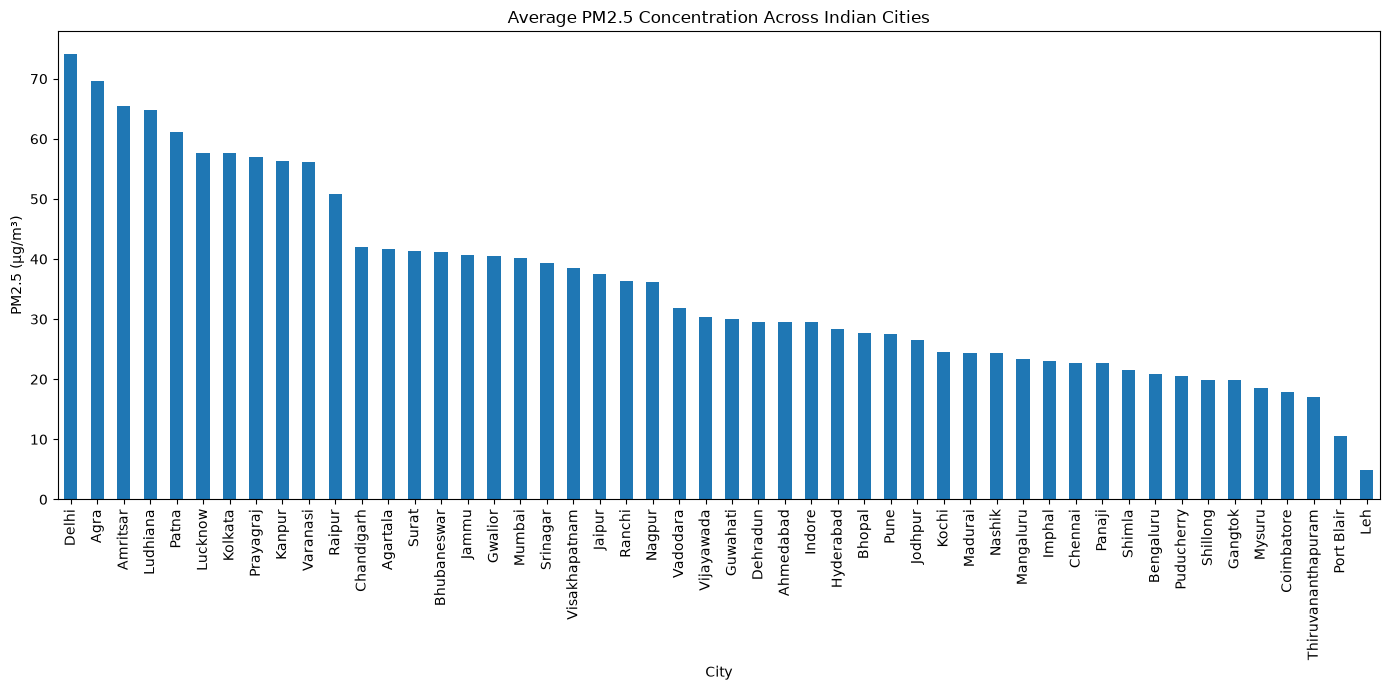

In [7]:
#Avg PM2.5 by city
city_pollution = (
    merged.groupby("city")["pm2_5_mean"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize = (14, 7))

city_pollution.plot(kind = "bar")

plt.title("Average PM2.5 Concentration Across Indian Cities")
plt.xlabel("City")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation = 90)
plt.tight_layout()
plt.show()

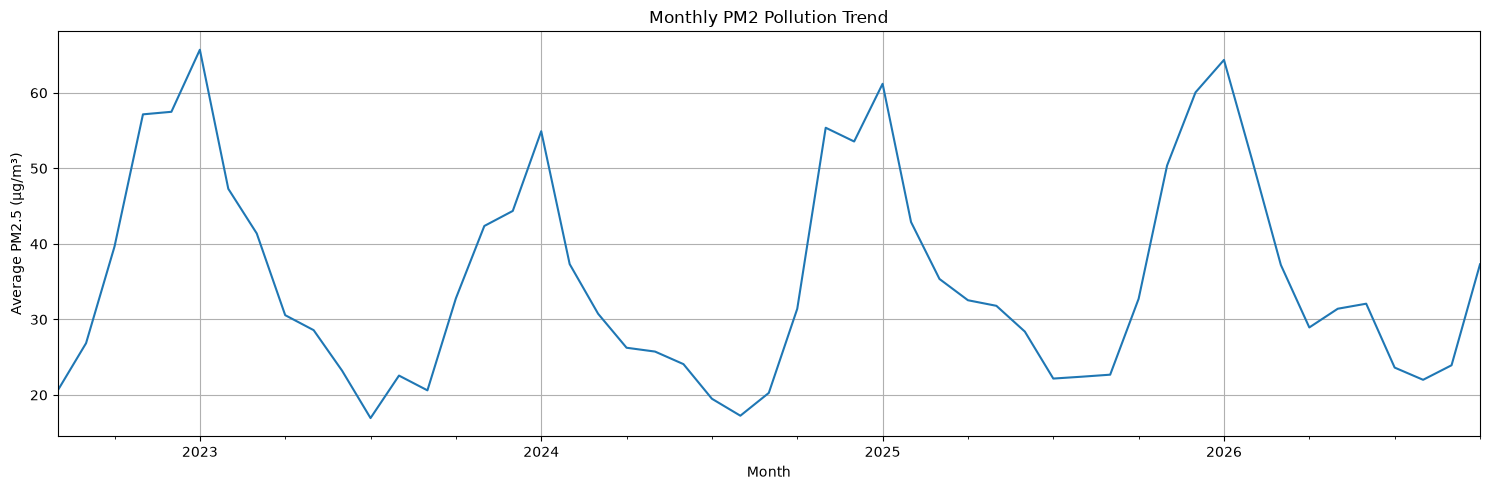

In [8]:
#Monthly population trend
monthly = merged.copy()

monthly["month_year"] = (
    monthly["date"].dt.to_period("M")
)

trend = monthly.groupby(
    "month_year"
)["pm2_5_mean"].mean()

plt.figure(figsize=(15, 5))

trend.plot()

plt.title("Monthly PM2 Pollution Trend")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.grid(True)
plt.tight_layout()
plt.show()

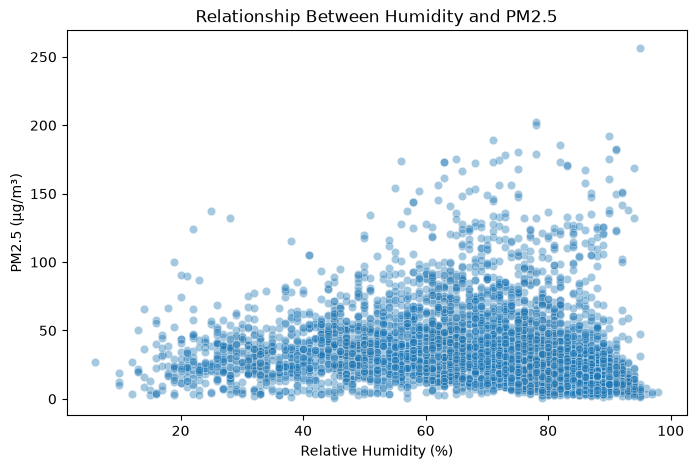

In [9]:
#Weather versus PM2.5
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=merged.sample(5000, random_state=42),
    x="relative_humidity_2m_mean",
    y="pm2_5_mean",
    alpha=0.4
)

plt.title("Relationship Between Humidity and PM2.5")
plt.xlabel("Relative Humidity (%)")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

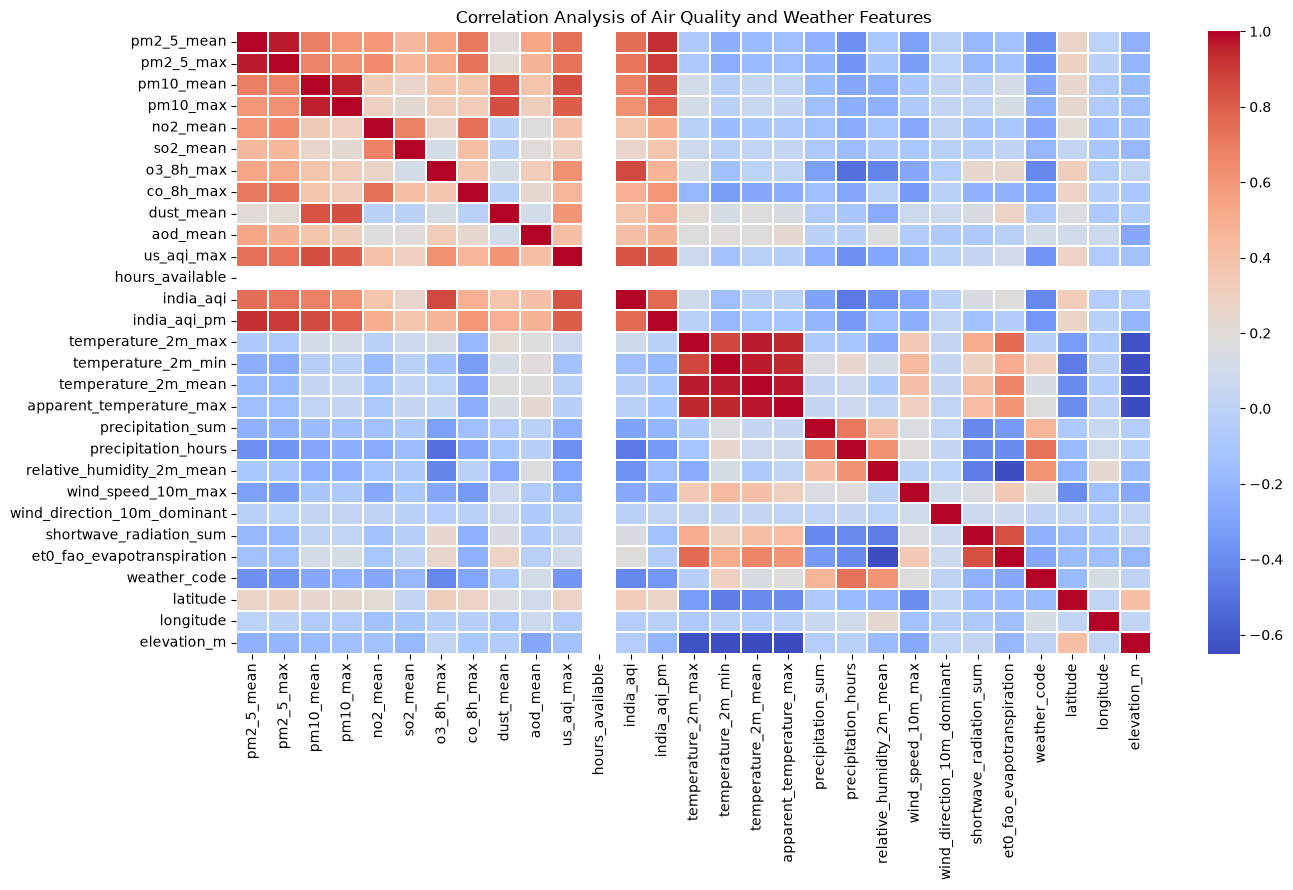

In [10]:
#Correlation heatmap
plt.figure(figsize=(14, 9))

numeric_data = merged.select_dtypes(include=np.number)

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Analysis of Air Quality and Weather Features")
plt.tight_layout()
plt.show()

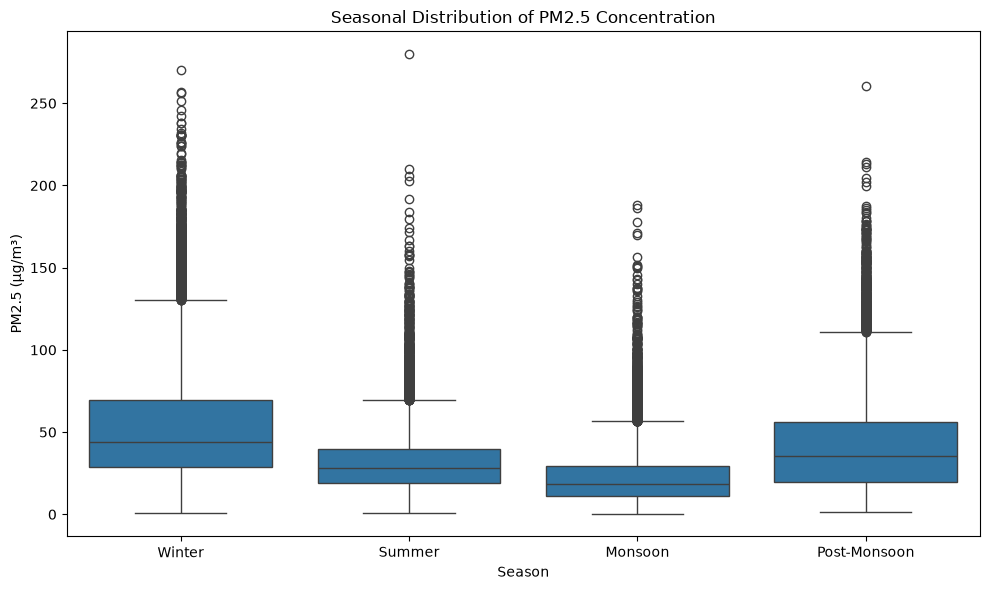

In [11]:
#Seasonal pollution distribution
merged["season"] = merged["date"].dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Summer", 4: "Summer", 5: "Summer",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon",
    9: "Monsoon", 10: "Post-Monsoon", 11: "Post-Monsoon"
})

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=merged,
    x="season",
    y="pm2_5_mean",
    order=["Winter", "Summer", "Monsoon", "Post-Monsoon"]
)

plt.title("Seasonal Distribution of PM2.5 Concentration")
plt.xlabel("Season")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

In [12]:
# Separate input features and target variable

target = "pm2_5_mean"

# Remove target and potentially target-derived features
drop_columns = [
    "pm2_5_mean",
    "pm2_5_max",
    "us_aqi_max",
    "india_aqi",
    "india_aqi_pm",
    "india_aqi_category",
    "india_aqi_pm_category",
    "dominant_pollutant",
    "date"
]

X = model_data.drop(
    columns=drop_columns,
    errors="ignore"
)

y = model_data[target]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

# Handle missing values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(X.columns.tolist())

Feature shape: (77400, 107)
Target shape: (77400,)

Selected features:
['pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'hours_available', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code', 'latitude', 'longitude', 'elevation_m', 'city_Agra', 'city_Ahmedabad', 'city_Amritsar', 'city_Bengaluru', 'city_Bhopal', 'city_Bhubaneswar', 'city_Chandigarh', 'city_Chennai', 'city_Coimbatore', 'city_Dehradun', 'city_Delhi', 'city_Gangtok', 'city_Guwahati', 'city_Gwalior', 'city_Hyderabad', 'city_Imphal', 'city_Indore', 'city_Jaipur', 'city_Jammu', 'city_Jodhpur', 'city_Kanpur', 'city_Kochi', 'city_Kolkata', 'city_Leh', 'city_Lucknow', 'city_Ludhiana', 'city_Madurai', 'city_Mangaluru', 'city_Mumbai', 'city_My

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training records: 61920
Testing records: 15480
Training features: (61920, 107)
Testing features: (15480, 107)


Model training and validation

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = StandardScaler()

print("Preprocessing method: Standard Scaling")
print("Number of input features:", X_train.shape[1])


Preprocessing method: Standard Scaling
Number of input features: 107


In [15]:
X_sub_train, X_val, y_sub_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_sub_train.shape)
print("Validation data:", X_val.shape)


Training data: (49536, 107)
Validation data: (12384, 107)


In [16]:
# Train three machine learning models

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=4
    )
}

validation_results = []
trained_pipelines = {}

for name, model in models.items():

    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_sub_train, y_sub_train)

    predictions = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    validation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_pipelines[name] = pipeline

    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))
    print("-" * 40)

validation_results_df = pd.DataFrame(validation_results)

print("\nValidation Results:")
display(validation_results_df)

Training: Linear Regression
MAE: 4.7955
RMSE: 7.0733
R2 Score: 0.9349
----------------------------------------
Training: Decision Tree
MAE: 4.0315
RMSE: 7.3558
R2 Score: 0.9296
----------------------------------------
Training: Random Forest
MAE: 4.3652
RMSE: 6.8031
R2 Score: 0.9398
----------------------------------------

Validation Results:


,Model,MAE,RMSE,R2
0,Linear Regression,4.795452,7.073280,0.934907
1,Decision Tree,4.031467,7.355838,0.929603
2,Random Forest,4.365240,6.803110,0.939785


Hyperparameter tuning

In [17]:
from sklearn.model_selection import ParameterGrid
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

param_grids = {
    "Decision Tree": {
        "max_depth": [10, 15, 20],
        "min_samples_leaf": [2, 5]
    },

    "Random Forest": {
        "n_estimators": [30, 50],
        "max_depth": [10, 12],
        "min_samples_leaf": [5],
        "max_features": ["sqrt"]
    }
}

best_tuned_models = {}
tuning_results = []

for name, param_grid in param_grids.items():

    best_rmse = float("inf")
    best_model = None
    best_params = None

    for params in ParameterGrid(param_grid):

        if name == "Decision Tree":
            model = DecisionTreeRegressor(
                **params,
                random_state=42
            )
        else:
            model = RandomForestRegressor(
                **params,
                random_state=42,
                n_jobs=4
            )

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        pipeline.fit(X_sub_train, y_sub_train)

        predictions = pipeline.predict(X_val)

        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )

        if rmse < best_rmse:
            best_rmse = rmse
            best_model = pipeline
            best_params = params

    best_tuned_models[name] = best_model

    tuning_results.append({
        "Model": name,
        "Best Parameters": best_params,
        "Best RMSE": best_rmse
    })

    print("\n", name)
    print("Best Parameters:", best_params)
    print("Best RMSE:", round(best_rmse, 4))

tuning_results_df = pd.DataFrame(tuning_results)
display(tuning_results_df)


 Decision Tree
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2}
Best RMSE: 7.2735

 Random Forest
Best Parameters: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 50}
Best RMSE: 6.8031


,Model,Best Parameters,Best RMSE
0,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 2}",7.273478
1,Random Forest,"{'max_depth': 12, 'max_features': 'sqrt', 'min...",6.803110


Final evaluation on the test dataset

In [18]:
# Final evaluation on test dataset

from sklearn.base import clone

final_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": clone(
        best_tuned_models["Decision Tree"].named_steps["model"]
    ),

    "Random Forest": clone(
        best_tuned_models["Random Forest"].named_steps["model"]
    )
}

final_results = []
final_pipelines = {}
test_predictions = {}

for name, model in final_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    final_pipelines[name] = pipeline
    test_predictions[name] = predictions

    print(f"\n{name}")
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2:", round(r2, 4))

results_df = pd.DataFrame(final_results).sort_values("RMSE")

display(results_df)


Linear Regression
MAE: 4.8484
RMSE: 7.357
R2: 0.9327

Decision Tree
MAE: 4.2826
RMSE: 7.186
R2: 0.9358

Random Forest
MAE: 4.3964
RMSE: 7.0565
R2: 0.9381


,Model,MAE,RMSE,R2
2,Random Forest,4.396402,7.056477,0.938129
1,Decision Tree,4.282588,7.186011,0.935836
0,Linear Regression,4.848399,7.356955,0.932747


Model comparison graph

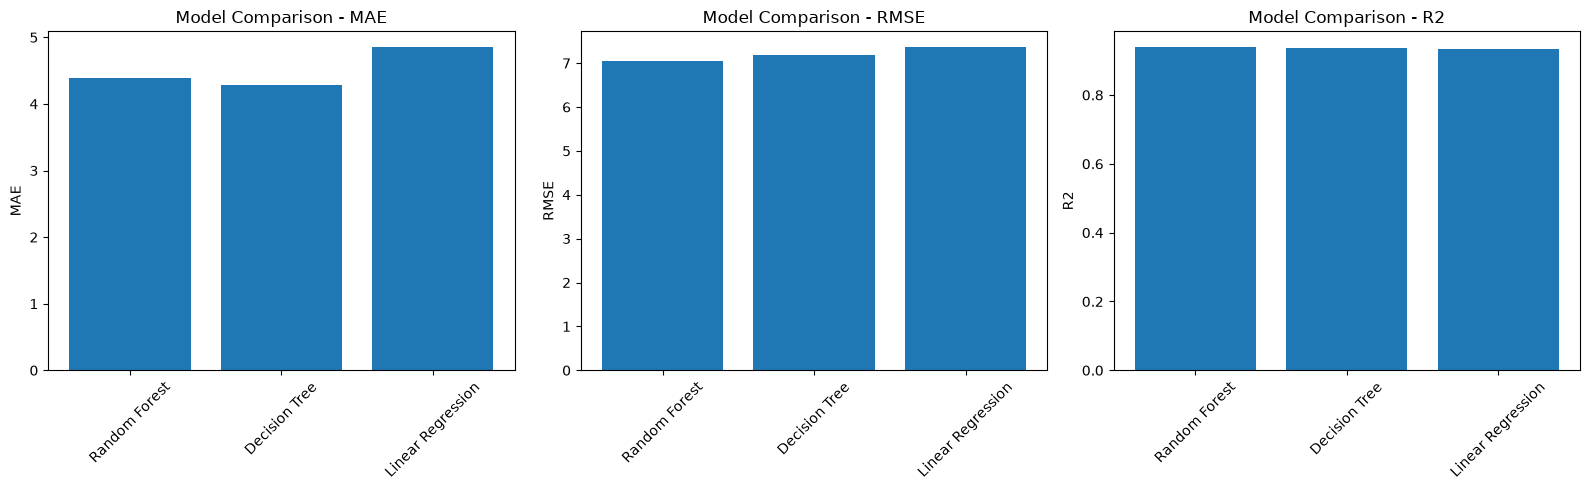

In [19]:
# Final Model Comparison

import matplotlib.pyplot as plt

comparison_df = results_df.copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):
    ax.bar(comparison_df["Model"], comparison_df[metric])
    ax.set_title(f"Model Comparison - {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Random Forest Feature Importance Analysis

Top 15 Important Features:


,Feature,Importance
0,pm10_mean,0.219049
1,pm10_max,0.198126
5,co_8h_max,0.105531
3,so2_mean,0.067522
4,o3_8h_max,0.050530
7,aod_mean,0.045305
2,no2_mean,0.041555
14,precipitation_hours,0.025187
20,weather_code,0.023344
19,et0_fao_evapotranspiration,0.019586


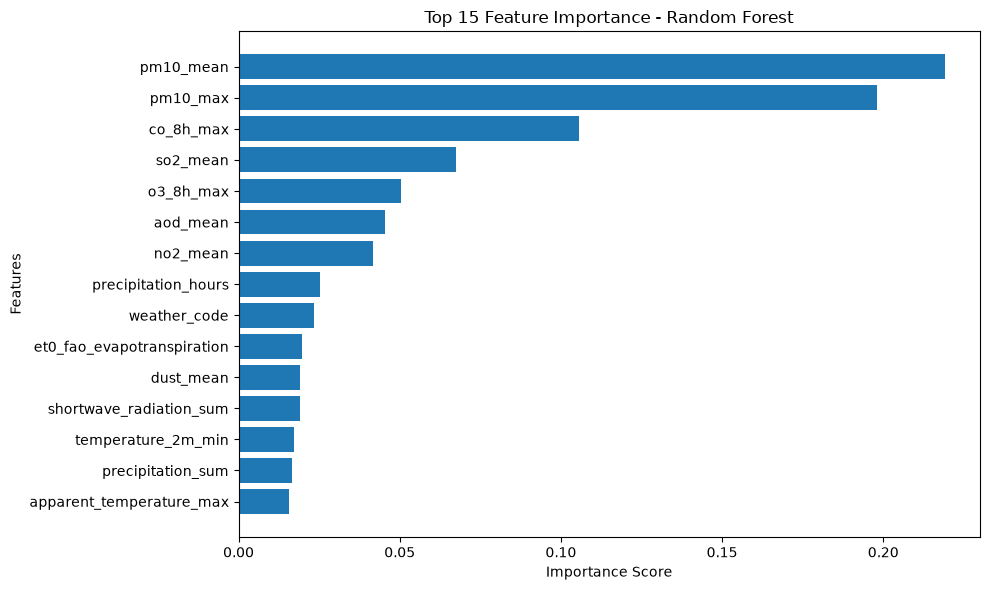

In [20]:
# Random Forest Feature Importance Analysis

rf_model = final_pipelines["Random Forest"].named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

# Plot feature importance

plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importance - Random Forest")

plt.tight_layout()
plt.show()

Actual vs Predicted graph

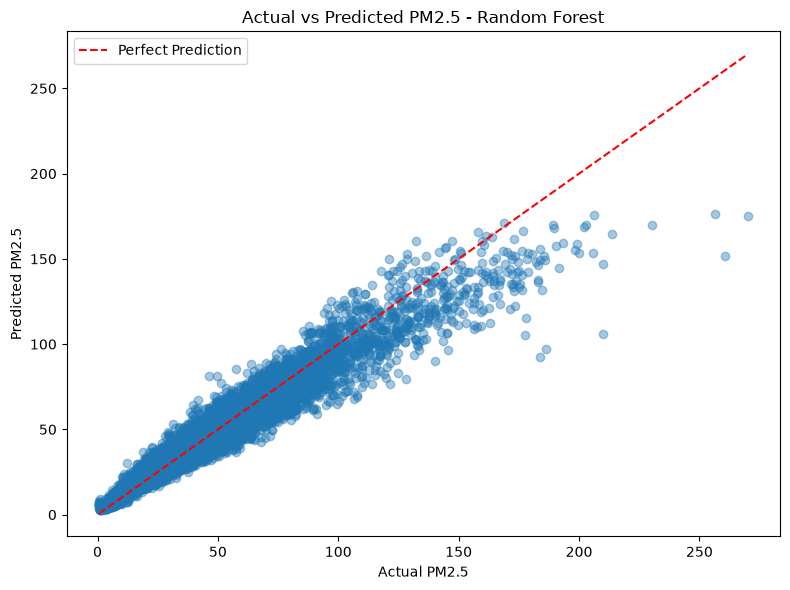

In [21]:
# Actual vs Predicted PM2.5 - Random Forest

best_model_name = "Random Forest"
best_predictions = test_predictions[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions, alpha=0.4)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted PM2.5 - Random Forest")

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.legend()
plt.tight_layout()
plt.show()

Residual Error Analysis

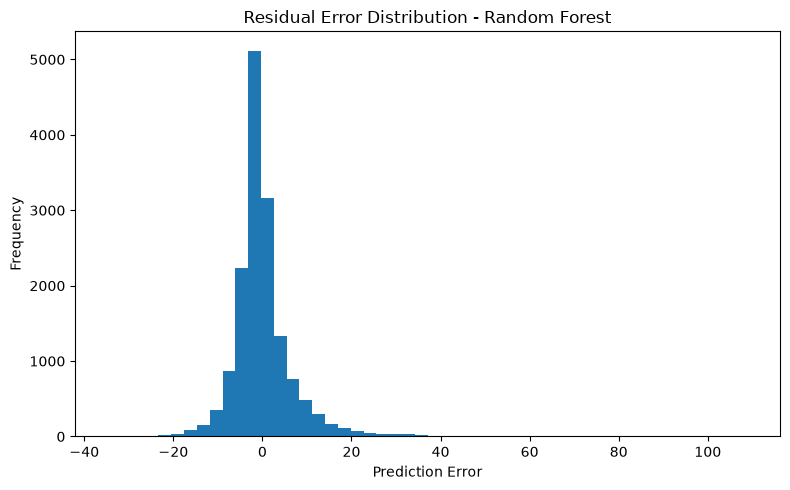

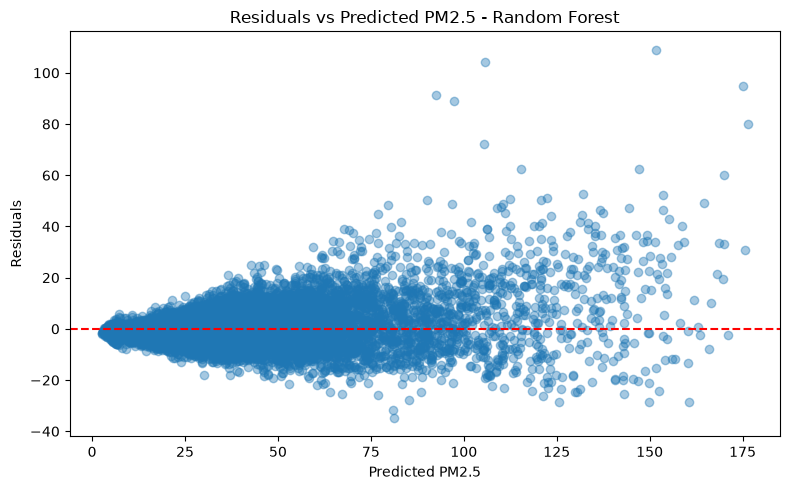

Mean Residual: 0.1026
Residual Standard Deviation: 7.056


In [22]:
# Residual Error Analysis - Random Forest

best_predictions = test_predictions["Random Forest"]

residuals = y_test - best_predictions

# Residual distribution
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=50)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Residual Error Distribution - Random Forest")

plt.tight_layout()
plt.show()


# Residuals vs Predicted Values
plt.figure(figsize=(8, 5))

plt.scatter(best_predictions, residuals, alpha=0.4)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted PM2.5")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted PM2.5 - Random Forest")

plt.tight_layout()
plt.show()

print("Mean Residual:", round(residuals.mean(), 4))
print("Residual Standard Deviation:", round(residuals.std(), 4))

Baseline Model

In [23]:
# Baseline Model - Mean Prediction

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Model: Mean Prediction")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2:", round(baseline_r2, 4))

Baseline Model: Mean Prediction
MAE: 20.2032
RMSE: 28.3757
R2: -0.0005


Permutation Feature Importance on Test Data


,Feature,Importance,Std
0,pm10_mean,4.70257,0.03404
1,pm10_max,3.40674,0.03037
5,co_8h_max,1.10529,0.00829
7,aod_mean,1.08099,0.01829
3,so2_mean,0.85486,0.01104
4,o3_8h_max,0.84746,0.00679
2,no2_mean,0.43930,0.00683
6,dust_mean,0.32036,0.00479
19,et0_fao_evapotranspiration,0.28021,0.00701
18,shortwave_radiation_sum,0.24075,0.00992


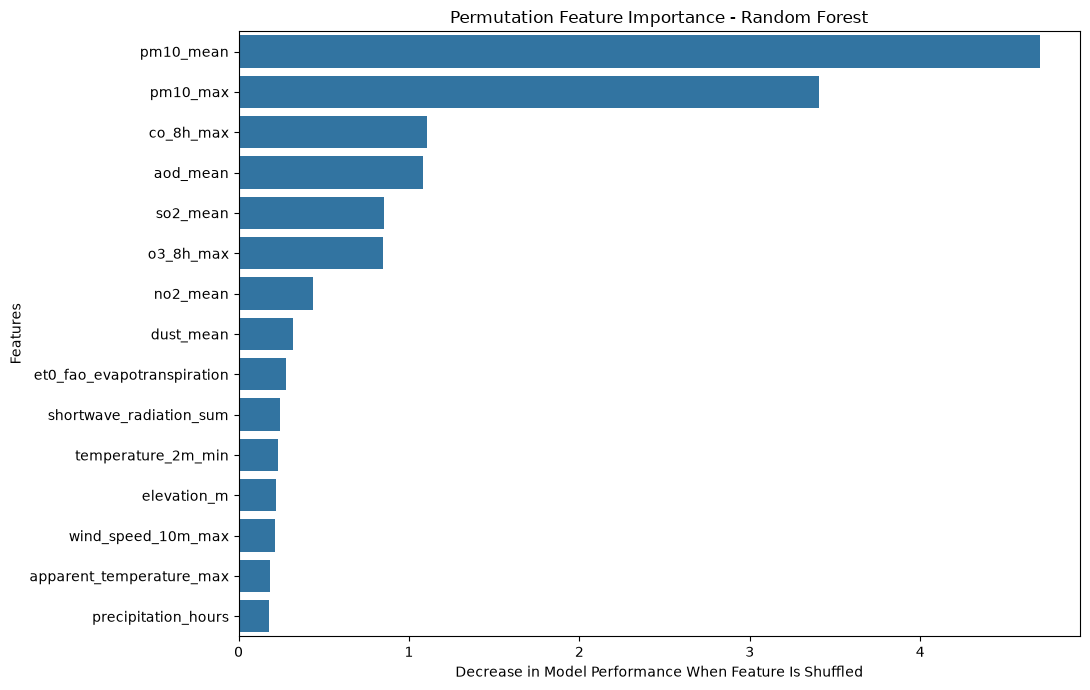

In [24]:
# Permutation Feature Importance on Test Data

from sklearn.inspection import permutation_importance

# Use the final trained Random Forest pipeline
rf_pipeline = final_pipelines["Random Forest"]

# Calculate permutation importance
perm_result = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

# Create importance dataframe
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(permutation_df.head(15).round(5))

# Plot top 15 features
plt.figure(figsize=(11, 7))

sns.barplot(
    data=permutation_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance - Random Forest")
plt.xlabel("Decrease in Model Performance When Feature Is Shuffled")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [25]:
# Save final trained models

import joblib

joblib.dump(final_pipelines, "all_models.joblib")

print("All trained models saved successfully!")

print("Available models:")
for name in final_pipelines.keys():
    print(name)

All trained models saved successfully!
Available models:
Linear Regression
Decision Tree
Random Forest


In [26]:
# Save test predictions

# Generate predictions using the final trained models
predictions_df = pd.DataFrame({
    "Actual_PM2.5": y_test.to_numpy(),
    "Linear_Regression": final_pipelines["Linear Regression"].predict(X_test),
    "Decision_Tree": final_pipelines["Decision Tree"].predict(X_test),
    "Random_Forest": final_pipelines["Random Forest"].predict(X_test)
})

# Save in the same folder as app.py
output_path = r"C:\Users\reddy\OneDrive\Desktop\ML\test_predictions.csv"

predictions_df.to_csv(output_path, index=False)

# Verify the saved file
print("File saved successfully!")
print("Location:", output_path)
print("Columns:", predictions_df.columns.tolist())
print("Shape:", predictions_df.shape)

display(predictions_df.head())


File saved successfully!
Location: C:\Users\reddy\OneDrive\Desktop\ML\test_predictions.csv
Columns: ['Actual_PM2.5', 'Linear_Regression', 'Decision_Tree', 'Random_Forest']
Shape: (15480, 4)


,Actual_PM2.5,Linear_Regression,Decision_Tree,Random_Forest
0,25.42,32.973581,29.353310,33.573934
1,33.59,40.687468,37.711389,38.677428
2,47.30,50.686279,46.688850,49.331658
3,41.08,34.201948,31.043281,33.565726
4,8.64,2.176471,9.799032,10.112095


In [27]:
# Generate prediction results with dashboard-compatible column names
import pandas as pd
predictions_df = pd.DataFrame({
    "Actual_PM2.5": y_test.to_numpy(),
    "Linear_Regression": final_pipelines["Linear Regression"].predict(X_test),
    "Decision_Tree": final_pipelines["Decision Tree"].predict(X_test),
    "Random_Forest": final_pipelines["Random Forest"].predict(X_test)
})

# Save to the project folder
output_path = r"C:\Users\reddy\OneDrive\Desktop\ML\test_predictions.csv"
predictions_df.to_csv(output_path, index=False)

# Verify the saved CSV
saved_df = pd.read_csv(output_path)

print("Prediction results saved successfully!")
print("Columns:", saved_df.columns.tolist())
print("Shape:", saved_df.shape)

display(saved_df.head())

Prediction results saved successfully!
Columns: ['Actual_PM2.5', 'Linear_Regression', 'Decision_Tree', 'Random_Forest']
Shape: (15480, 4)


,Actual_PM2.5,Linear_Regression,Decision_Tree,Random_Forest
0,25.42,32.973581,29.353310,33.573934
1,33.59,40.687468,37.711389,38.677428
2,47.30,50.686279,46.688850,49.331658
3,41.08,34.201948,31.043281,33.565726
4,8.64,2.176471,9.799032,10.112095


In [28]:
print(predictions_df.columns.tolist())
print(predictions_df.shape)

['Actual_PM2.5', 'Linear_Regression', 'Decision_Tree', 'Random_Forest']
(15480, 4)
